# Avance 2. Ingeniería de características
## Sistema de conteo de productos Vetlife — Equipo 32

**Fecha:** 10 de octubre de 2026  
**Datos:** colección actualizada de fotografías de productos convertidas a JPG  
**Objetivo:** caracterizar la calidad visual de las imágenes, construir variables derivadas, codificar categorías, transformar y escalar variables, y reducir redundancia mediante selección y PCA.

> **Alcance:** en la carpeta de esta versión hay fotografías, pero no archivos de anotación YOLO asociados. Por ello, este avance trabaja con descriptores globales de cada imagen para la fase de preparación y auditoría; no estima clases ni cantidad de productos. Estos descriptores no sustituyen los píxeles ni las cajas/máscaras que requiere YOLO para aprender detección o segmentación.

## 1. Relación con el Avance 1 y planteamiento

El Avance 1 analizó una muestra previamente anotada y mostró la importancia de validar las máscaras antes de entrenar. Para este segundo avance se toma como fuente la colección de fotografías actualizada disponible en `imagenes_jpg/`. Las fotos son observaciones nuevas/enriquecidas para este análisis; no se asume que las etiquetas de la versión anterior describan automáticamente esta colección.

Cada fila de la tabla representa una fotografía. Se generan variables de tamaño y proporción, color, iluminación, textura y nitidez. Son medidas reproducibles que ayudan a detectar variación entre capturas y a documentar la preparación. Sin etiquetas correspondientes, no es posible probar si una variable predice una clase o el conteo de productos; por tanto, la selección se basa en varianza y redundancia, y la extracción en PCA.

**Preguntas de preparación:**

1. ¿Qué variación de formato, orientación, iluminación y textura hay en las fotos?
2. ¿Qué variables tienen asimetría suficiente para justificar una transformación?
3. ¿Qué variables son constantes o redundantes?
4. ¿Cuántos componentes explican al menos 90 % de la variación de estos descriptores?

## 2. Dependencias y decisiones de procesamiento

Este notebook usa Python, Pillow, NumPy, pandas, Matplotlib, seaborn y scikit-learn. Se recomienda Python 3.10 o posterior con versiones recientes de esas bibliotecas.

| Decisión | Aplicación | Justificación |
|---|---|---|
| Miniatura de análisis | Reducir el lado mayor a 512 px al calcular descriptores; conservar ancho/alto y tamaño del original | Mantiene el análisis manejable y comparable; no reemplaza el JPG original para etiquetar o entrenar |
| Intensidades | Convertir RGB de `uint8` `[0,255]` a `float32` `[0,1]` | Hace comparables las medidas de color e iluminación entre imágenes |
| Variables derivadas | Proporción, megapíxeles, bytes por megapíxel, brillo percentil, saturación, entropía, bordes y fracciones de sombra/altas luces | Capturan atributos globales de calidad/escena útiles para auditar fotografías |
| Categorías | Orientación y tercil de brillo; codificación one-hot | No se impone un orden numérico artificial a categorías nominales |
| Transformación | Yeo–Johnson sólo si la asimetría absoluta observada supera 1 | Admite ceros y valores positivos; se aplica según evidencia de la distribución, no de forma indiscriminada |
| Escalamiento | `StandardScaler` para las variables numéricas retenidas | Evita que las unidades y rangos dominen PCA y algoritmos sensibles a escala |
| Selección/extracción | Umbral de varianza cero, correlación de Spearman y PCA al 90 % | Retira constantes, reduce redundancia monotónica y resume variación multivariada |

**Nota sobre el uso en YOLO:** el modelo de detección aprende representaciones de los píxeles. Estas variables describen la imagen completa y se usan aquí como control de calidad/ejercicio de preparación; no se concatenan a YOLO ni se afirma que mejoren su precisión sin una evaluación con etiquetas.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, UnidentifiedImageError
from scipy.ndimage import laplace
from IPython.display import display
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
SEED = 42

## 3. Carga y auditoría inicial

El notebook busca `imagenes_jpg/` en la carpeta de trabajo o en su carpeta padre, de modo que se puede ejecutar desde la raíz del proyecto o desde `avances/`. Si se comparte el notebook sin las fotografías, se debe colocar localmente la carpeta de JPG convertidos en una de esas ubicaciones. No se incluyen las fotos dentro de las salidas del notebook.

In [2]:
possible_dirs = [Path.cwd() / "imagenes_jpg", Path.cwd().parent / "imagenes_jpg"]
IMAGE_DIR = next((p for p in possible_dirs if p.is_dir()), None)
if IMAGE_DIR is None:
    raise FileNotFoundError(
        "No se encontró la carpeta imagenes_jpg/. Colócala junto a este notebook "
        "o en la carpeta del proyecto y vuelve a ejecutar."
    )

SUPPORTED_EXTS = {".jpg", ".jpeg", ".png"}
image_paths = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTS
)
if not image_paths:
    raise FileNotFoundError(f"No hay archivos JPG/JPEG/PNG en {IMAGE_DIR.name}/")

print(f"Archivos de imagen encontrados: {len(image_paths)}")
print(f"Formatos: {dict(pd.Series([p.suffix.lower() for p in image_paths]).value_counts())}")

Archivos de imagen encontrados: 282
Formatos: {'.jpg': np.int64(282)}


## 4. Ingeniería de características por fotografía

Se corrige la orientación EXIF antes de medir dimensiones. El muestreo de píxeles se limita a miniaturas para reducir tiempo y memoria. Las medidas de bordes y Laplaciano son aproximaciones de textura/nitidez: dependen de escala y compresión, por lo que se interpretan de forma comparativa dentro de esta colección.

| Grupo | Características |
|---|---|
| Geometría y almacenamiento | ancho, alto, orientación, proporción ancho/alto, megapíxeles, tamaño en MB, bytes por megapíxel |
| Color e iluminación | medias RGB, dispersión RGB media, brillo medio/desviación/percentiles, saturación media |
| Textura y exposición | entropía en escala de grises, intensidad media de gradiente, densidad de bordes, varianza del Laplaciano, fracción de sombras y altas luces |

In [3]:
def entropy_bits(gray_u8):
    counts = np.bincount(gray_u8.ravel(), minlength=256).astype(np.float64)
    probs = counts[counts > 0] / counts.sum()
    return float(-(probs * np.log2(probs)).sum())


def extract_image_features(path, index):
    with Image.open(path) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
        width, height = image.size
        image.thumbnail((512, 512), Image.Resampling.LANCZOS)
        rgb_u8 = np.asarray(image, dtype=np.uint8)

    rgb = rgb_u8.astype(np.float32) / 255.0
    red, green, blue = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    max_rgb = rgb.max(axis=2)
    min_rgb = rgb.min(axis=2)
    saturation = np.divide(
        max_rgb - min_rgb, max_rgb,
        out=np.zeros_like(max_rgb), where=max_rgb > 1e-8
    )
    # Aproximación de luminancia en RGB normalizado.
    gray = 0.2126 * red + 0.7152 * green + 0.0722 * blue
    gray_u8 = np.clip(gray * 255, 0, 255).astype(np.uint8)
    gy, gx = np.gradient(gray)
    gradient = np.hypot(gx, gy)
    file_bytes = path.stat().st_size
    megapixels = (width * height) / 1_000_000

    return {
        "image_id": f"img_{index:03d}",
        "width_px": width,
        "height_px": height,
        "orientation": "horizontal" if width > height else "vertical" if height > width else "cuadrada",
        "aspect_ratio": width / height,
        "megapixels": megapixels,
        "file_size_mb": file_bytes / (1024 ** 2),
        "bytes_per_megapixel": file_bytes / megapixels if megapixels else np.nan,
        "red_mean": float(red.mean()),
        "green_mean": float(green.mean()),
        "blue_mean": float(blue.mean()),
        "rgb_std_mean": float(np.mean([red.std(), green.std(), blue.std()])),
        "brightness_mean": float(gray.mean()),
        "contrast_std": float(gray.std()),
        "brightness_p05": float(np.quantile(gray, 0.05)),
        "brightness_p95": float(np.quantile(gray, 0.95)),
        "mean_saturation": float(saturation.mean()),
        "gray_entropy_bits": entropy_bits(gray_u8),
        "edge_strength_mean": float(gradient.mean()),
        "edge_density_010": float((gradient >= 0.10).mean()),
        "laplacian_variance": float(laplace(gray).var()),
        "shadow_fraction": float((gray < 0.15).mean()),
        "highlight_fraction": float((gray > 0.90).mean()),
    }

rows, unreadable = [], []
for idx, path in enumerate(image_paths, start=1):
    try:
        rows.append(extract_image_features(path, idx))
    except (UnidentifiedImageError, OSError, ValueError) as exc:
        unreadable.append({"image_id": f"img_{idx:03d}", "reason": type(exc).__name__})

images_df = pd.DataFrame(rows)
unreadable_df = pd.DataFrame(unreadable, columns=["image_id", "reason"])
if images_df.empty:
    raise ValueError("No se pudo leer ninguna imagen.")

print(f"Imágenes legibles: {len(images_df)} de {len(image_paths)}")
print(f"Imágenes ilegibles: {len(unreadable_df)}")
if not unreadable_df.empty:
    display(unreadable_df)
display(images_df.head().drop(columns=["image_id"]))

Imágenes legibles: 282 de 282
Imágenes ilegibles: 0


,width_px,height_px,orientation,aspect_ratio,megapixels,file_size_mb,bytes_per_megapixel,red_mean,green_mean,blue_mean,rgb_std_mean,brightness_mean,contrast_std,brightness_p05,brightness_p95,mean_saturation,gray_entropy_bits,edge_strength_mean,edge_density_010,laplacian_variance,shadow_fraction,highlight_fraction
0,2160,3840,vertical,0.562500,8.2944,1.716419,216989.293981,0.490842,0.456055,0.434878,0.252726,0.461922,0.248148,0.060795,0.910180,0.186842,7.635281,0.052526,0.157376,0.043005,0.066630,0.060533
1,3840,2160,horizontal,1.777778,8.2944,1.812301,229110.604745,0.516228,0.528334,0.509734,0.271145,0.524418,0.266134,0.099217,0.923441,0.175580,7.920438,0.079513,0.279114,0.081252,0.095852,0.067525
2,2160,3840,vertical,0.562500,8.2944,1.294116,163601.827739,0.453559,0.459981,0.433874,0.243522,0.456731,0.240849,0.118094,0.897205,0.232793,7.663785,0.039539,0.121453,0.023960,0.087579,0.048862
3,2160,3840,vertical,0.562500,8.2944,1.746317,220768.952546,0.472527,0.443321,0.422670,0.243917,0.448039,0.239611,0.062462,0.887495,0.180382,7.622638,0.050329,0.146383,0.039623,0.073412,0.037055
4,2160,3840,vertical,0.562500,8.2944,1.650825,208696.831597,0.609438,0.607190,0.599065,0.189693,0.607081,0.188938,0.244506,0.850471,0.059723,7.462478,0.033013,0.097080,0.024953,0.020087,0.017198


## 5. Resumen de calidad y distribuciones

Se revisan dimensiones, orientación y valores faltantes antes de transformar. Los posibles extremos se conservan: pueden reflejar una toma genuinamente distinta (por ejemplo, brillo o encuadre) y no se deben eliminar sin inspeccionar la causa.

In [4]:
feature_cols = [
    "aspect_ratio", "megapixels", "file_size_mb", "bytes_per_megapixel",
    "red_mean", "green_mean", "blue_mean", "rgb_std_mean",
    "brightness_mean", "contrast_std", "brightness_p05", "brightness_p95",
    "mean_saturation", "gray_entropy_bits", "edge_strength_mean",
    "edge_density_010", "laplacian_variance", "shadow_fraction", "highlight_fraction",
]

print("Dimensiones originales más frecuentes:")
display(
    images_df.groupby(["width_px", "height_px"], as_index=False)
    .size().sort_values("size", ascending=False).head(8)
)
print("Orientación:")
display(images_df["orientation"].value_counts().rename_axis("orientación").to_frame("fotos"))
print("Valores faltantes en descriptores:", int(images_df[feature_cols].isna().sum().sum()))
print(f"Tamaño medio del archivo: {images_df['file_size_mb'].mean():.2f} MB")
print(f"Proporción ancho/alto — mediana: {images_df['aspect_ratio'].median():.3f}; rango: {images_df['aspect_ratio'].min():.3f}–{images_df['aspect_ratio'].max():.3f}")

display(images_df[feature_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(4))

Dimensiones originales más frecuentes:


,width_px,height_px,size
1,3024,4032,244
3,4032,3024,28
0,2160,3840,9
2,3840,2160,1


Orientación:


,fotos
orientación,
vertical,253
horizontal,29


Valores faltantes en descriptores: 0
Tamaño medio del archivo: 2.79 MB
Proporción ancho/alto — mediana: 0.750; rango: 0.562–1.778


,mean,std,min,50%,max
aspect_ratio,0.8056,0.1889,0.5625,0.7500,1.7778
megapixels,12.0545,0.7223,8.2944,12.1928,12.1928
file_size_mb,2.7906,0.3707,1.2941,2.8178,3.7157
bytes_per_megapixel,242224.8735,26196.3269,163601.8277,242326.9269,319550.6549
red_mean,0.4923,0.0491,0.3948,0.4850,0.6548
green_mean,0.4803,0.0540,0.3916,0.4693,0.6616
blue_mean,0.4618,0.0575,0.3761,0.4484,0.6512
rgb_std_mean,0.2447,0.0367,0.1092,0.2487,0.3178
brightness_mean,0.4815,0.0527,0.3913,0.4715,0.6591
contrast_std,0.2431,0.0362,0.1118,0.2464,0.3156


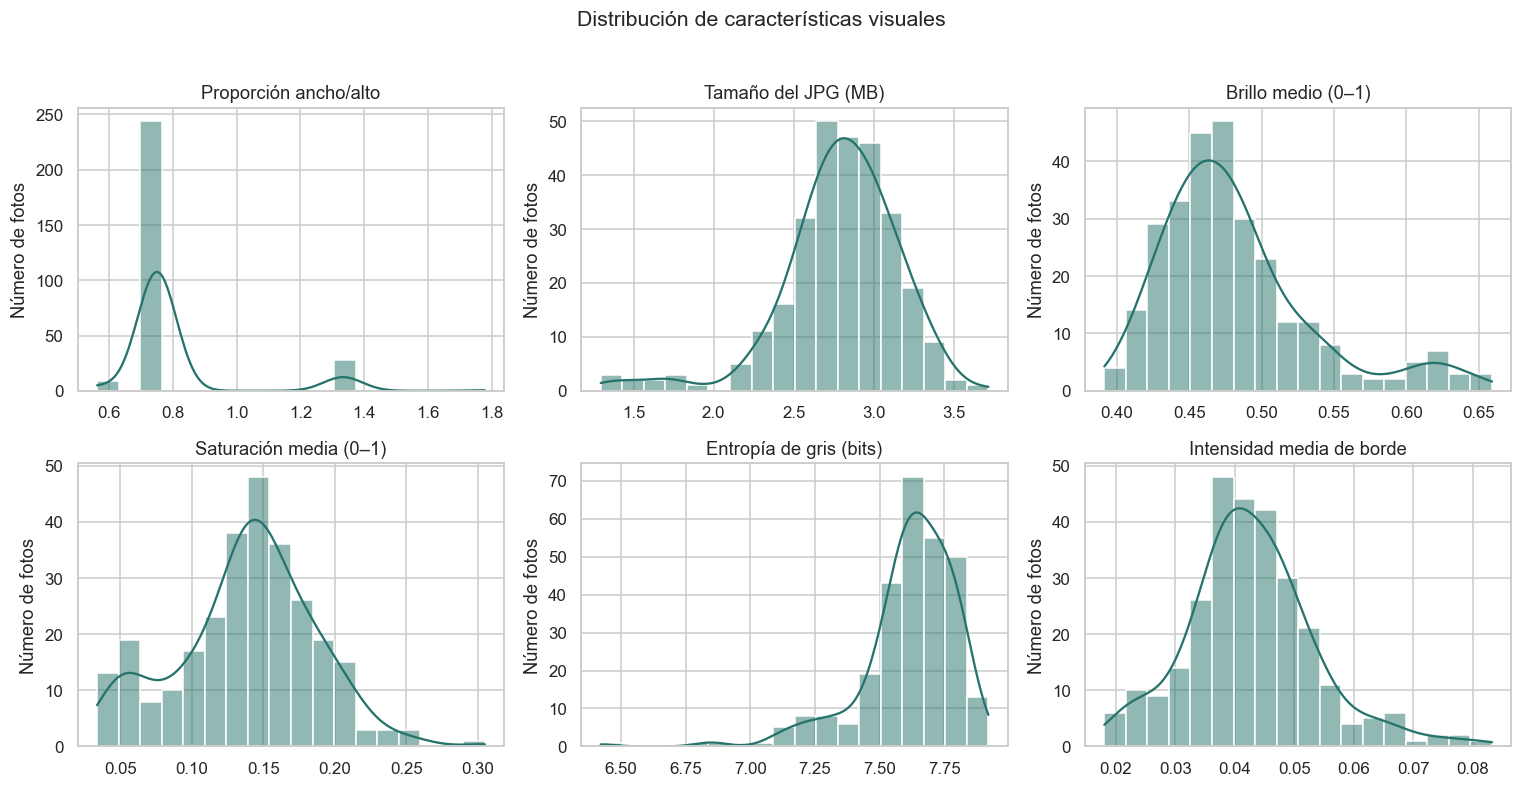

In [5]:
plot_cols = [
    ("aspect_ratio", "Proporción ancho/alto"),
    ("file_size_mb", "Tamaño del JPG (MB)"),
    ("brightness_mean", "Brillo medio (0–1)"),
    ("mean_saturation", "Saturación media (0–1)"),
    ("gray_entropy_bits", "Entropía de gris (bits)"),
    ("edge_strength_mean", "Intensidad media de borde"),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axes.flat, plot_cols):
    sns.histplot(images_df[col].dropna(), bins=18, kde=True, ax=ax, color="#26736b")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("Número de fotos")
fig.suptitle("Distribución de características visuales", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

### Hallazgos descriptivos

Los histogramas y la tabla anterior permiten distinguir cambios de encuadre, iluminación y textura. Las variables de sombra/altas luces describen extremos de exposición; no se tratan como etiquetas de defecto. La entropía y gradientes dependen del contenido y del tamaño de miniatura, así que sirven como señales comparativas, no como diagnóstico absoluto de una foto.

## 6. Discretización y codificación de variables categóricas

Se construye una categoría de brillo con tres grupos definidos por terciles de la muestra y se conserva orientación como categoría nominal. Se usa one-hot encoding para representar cada categoría mediante indicadores, sin asumir que “vertical” sea mayor o menor que “horizontal”. Los puntos de corte se estiman aquí para describir esta colección; al desplegar un proceso predictivo deben calcularse sólo con el conjunto de entrenamiento.

In [6]:
images_df["brightness_band"], brightness_breaks = pd.qcut(
    images_df["brightness_mean"], q=3,
    labels=["baja", "media", "alta"], duplicates="drop", retbins=True
)
cat_df = images_df[["orientation", "brightness_band"]].astype("category")
encoded_categories = pd.get_dummies(
    cat_df, prefix=["orientacion", "brillo"], dtype="int8"
)

print("Puntos de corte de brillo (terciles, escala 0–1):", np.round(brightness_breaks, 3).tolist())
print("Frecuencias de las categorías construidas:")
display(images_df["brightness_band"].value_counts().sort_index().rename("fotos").to_frame())
print("Columnas one-hot:", list(encoded_categories.columns))
display(encoded_categories.sum().rename("frecuencia").to_frame())

Puntos de corte de brillo (terciles, escala 0–1): [0.391, 0.455, 0.488, 0.659]
Frecuencias de las categorías construidas:


,fotos
brightness_band,
baja,94
media,94
alta,94


Columnas one-hot: ['orientacion_horizontal', 'orientacion_vertical', 'brillo_baja', 'brillo_media', 'brillo_alta']


,frecuencia
orientacion_horizontal,29
orientacion_vertical,253
brillo_baja,94
brillo_media,94
brillo_alta,94


## 7. Transformación según asimetría

Se evalúa la asimetría de cada variable numérica. Si `|asimetría| > 1`, se aplica Yeo–Johnson con `standardize=False`; el escalamiento se realiza después. Yeo–Johnson admite ceros y variables con valores negativos, a diferencia de Box–Cox, por lo que no requiere sumar una constante artificial. La decisión es una regla exploratoria para este conjunto, no una garantía de normalidad ni una transformación aplicada a los píxeles originales.

In [7]:
X_raw = images_df[feature_cols].replace([np.inf, -np.inf], np.nan)
if X_raw.isna().any().any():
    # Las medidas se derivan directamente de imágenes legibles; no se imputan silenciosamente.
    missing = X_raw.columns[X_raw.isna().any()].tolist()
    raise ValueError(f"Hay valores faltantes en características: {missing}")

skew_before = X_raw.skew().rename("asimetria_original")
transform_cols = skew_before[skew_before.abs() > 1].index.tolist()
X_transformed = X_raw.copy()
transformers = {}
for col in transform_cols:
    transformer = PowerTransformer(method="yeo-johnson", standardize=False)
    X_transformed[col] = transformer.fit_transform(X_raw[[col]]).ravel()
    transformers[col] = transformer

skew_comparison = pd.concat(
    [skew_before, X_transformed.skew().rename("asimetria_transformada")], axis=1
)
skew_comparison["transformacion"] = [
    "Yeo–Johnson" if col in transform_cols else "Sin transformación"
    for col in skew_comparison.index
]
print(f"Variables transformadas por |asimetría| > 1: {len(transform_cols)}")
display(skew_comparison.round(3).sort_values("asimetria_original", key=lambda s: s.abs(), ascending=False))

Variables transformadas por |asimetría| > 1: 11


,asimetria_original,asimetria_transformada,transformacion
megapixels,-5.051,-5.051,Yeo–Johnson
aspect_ratio,2.585,-0.482,Yeo–Johnson
gray_entropy_bits,-1.964,-0.066,Yeo–Johnson
brightness_p05,1.715,0.033,Yeo–Johnson
brightness_mean,1.305,0.055,Yeo–Johnson
green_mean,1.281,0.073,Yeo–Johnson
file_size_mb,-1.201,0.055,Yeo–Johnson
blue_mean,1.192,0.096,Yeo–Johnson
red_mean,1.189,-0.022,Yeo–Johnson
shadow_fraction,1.055,0.053,Yeo–Johnson


## 8. Selección de características

Se usan dos filtros complementarios:

1. **Varianza:** `VarianceThreshold(0)` elimina variables constantes, que no distinguen observaciones.
2. **Correlación de Spearman:** se identifica redundancia monotónica con `|ρ| > 0.90`. Para hacer la decisión reproducible, se recorre un orden de prioridad que conserva primero las medidas más interpretables y retira después una medida altamente correlacionada con una ya conservada. El corte de 0.90 es una regla de reducción de redundancia, no evidencia de causalidad.

No se aplican chi-cuadrado ni ANOVA porque esta versión no tiene variable objetivo/clases válidas para las 282 imágenes. Usarlos sin etiquetas produciría una selección sin fundamento.

Eliminadas por varianza cero: ninguna


Variables antes de correlación: 19
Variables conservadas: 12


,variable_retirada,se_conserva,abs_rho_spearman
0,bytes_per_megapixel,file_size_mb,0.997
1,blue_mean,green_mean,0.962
2,brightness_mean,green_mean,0.997
3,contrast_std,rgb_std_mean,0.996
4,edge_density_010,edge_strength_mean,0.929
5,shadow_fraction,brightness_p05,0.957
6,highlight_fraction,brightness_p95,0.962


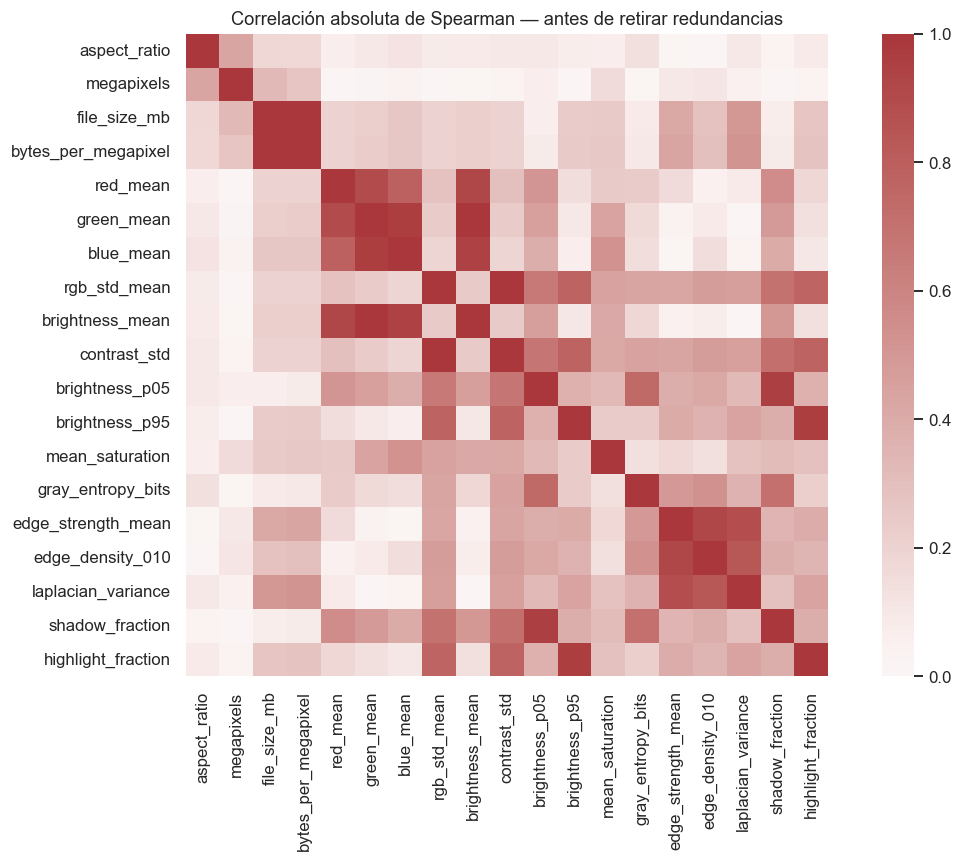

In [8]:
variance_filter = VarianceThreshold(threshold=0.0)
X_var_array = variance_filter.fit_transform(X_transformed)
variance_kept = X_transformed.columns[variance_filter.get_support()].tolist()
variance_removed = [c for c in X_transformed.columns if c not in variance_kept]
X_var = X_transformed[variance_kept].copy()
print("Eliminadas por varianza cero:", variance_removed if variance_removed else "ninguna")

corr_spearman = X_var.corr(method="spearman").abs()
priority_order = [c for c in feature_cols if c in X_var.columns]
kept_corr, removed_corr = [], []
for col in priority_order:
    conflicting = [prior for prior in kept_corr if corr_spearman.loc[col, prior] > 0.90]
    if conflicting:
        prior = max(conflicting, key=lambda name: corr_spearman.loc[col, name])
        removed_corr.append({
            "variable_retirada": col,
            "se_conserva": prior,
            "abs_rho_spearman": corr_spearman.loc[col, prior],
        })
    else:
        kept_corr.append(col)

removed_corr_df = pd.DataFrame(
    removed_corr, columns=["variable_retirada", "se_conserva", "abs_rho_spearman"]
)
print(f"Variables antes de correlación: {len(variance_kept)}")
print(f"Variables conservadas: {len(kept_corr)}")
if removed_corr_df.empty:
    print("No se encontraron pares sobre el umbral 0.90.")
else:
    display(removed_corr_df.round(3))

plt.figure(figsize=(11, 8))
sns.heatmap(corr_spearman, cmap="vlag", center=0, vmin=0, vmax=1, square=True)
plt.title("Correlación absoluta de Spearman — antes de retirar redundancias")
plt.tight_layout()
plt.show()

## 9. Escalamiento y extracción con PCA

Después de transformar y seleccionar, `StandardScaler` centra cada variable en cero y la escala a desviación estándar uno. PCA se ajusta a esa matriz estandarizada y se retienen los componentes necesarios para explicar al menos 90 % de la varianza acumulada. PCA facilita resumir y visualizar estructura, pero los componentes son combinaciones de variables y pierden parte de la interpretación directa.

En una evaluación predictiva posterior, el ajuste de Yeo–Johnson, selección, escalador y PCA debe hacerse sólo con el conjunto de entrenamiento y aplicarse sin reajustar a validación/prueba, para evitar fuga de información.

Forma de la matriz numérica estandarizada: (282, 12)


,mean,std,min,max
aspect_ratio,-0.0,1.002,-3.759,2.501
megapixels,-0.0,1.002,-5.215,0.192
file_size_mb,-0.0,1.002,-2.714,3.627
red_mean,-0.0,1.002,-3.035,2.352
green_mean,-0.0,1.002,-2.654,2.186
rgb_std_mean,-0.0,1.002,-3.693,1.993
brightness_p05,-0.0,1.002,-3.272,2.520
brightness_p95,-0.0,1.002,-2.930,2.123
mean_saturation,-0.0,1.002,-2.168,3.459
gray_entropy_bits,-0.0,1.002,-2.663,2.663


Componentes para explicar ≥90 %: 6 de 12
Varianza explicada acumulada: 0.905
Varianza explicada por PC1: 0.390


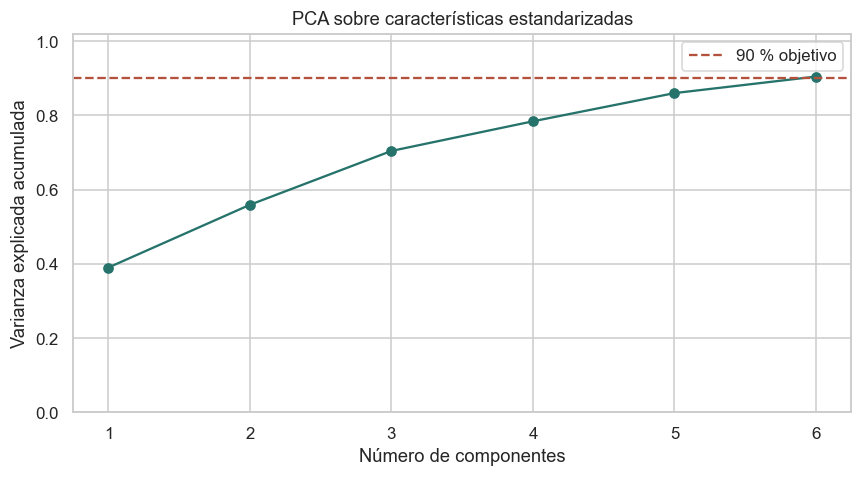

In [9]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_transformed[kept_corr]),
    columns=kept_corr, index=images_df["image_id"]
)
print("Forma de la matriz numérica estandarizada:", X_scaled.shape)
display(X_scaled.describe().T[["mean", "std", "min", "max"]].round(3))

pca = PCA(n_components=0.90, svd_solver="full", random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
cumulative = np.cumsum(pca.explained_variance_ratio_)
print(f"Componentes para explicar ≥90 %: {pca.n_components_} de {X_scaled.shape[1]}")
print(f"Varianza explicada acumulada: {cumulative[-1]:.3f}")
print(f"Varianza explicada por PC1: {pca.explained_variance_ratio_[0]:.3f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
components = np.arange(1, len(cumulative) + 1)
ax.plot(components, cumulative, marker="o", color="#26736b")
ax.axhline(0.90, color="#b4513c", linestyle="--", label="90 % objetivo")
ax.set_xticks(components)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Número de componentes")
ax.set_ylabel("Varianza explicada acumulada")
ax.set_title("PCA sobre características estandarizadas")
ax.legend()
plt.tight_layout()
plt.show()

### Lectura de componentes

El número final de componentes se determina por los datos y el umbral de 90 %. La reducción de 19 descriptores iniciales a las variables no redundantes y después a un espacio PCA más compacto ilustra cómo bajar dimensionalidad para análisis numérico. Para entrenar YOLO se conservarán las imágenes y anotaciones, no la matriz PCA de descriptores globales.

## 10. Conclusiones de Preparación de Datos en CRISP-ML(Q)

En CRISP-ML(Q), la preparación convierte datos disponibles en entradas consistentes y verificables para el modelado. Para esta versión, la colección actualizada permite medir orientación, encuadre, exposición, color y textura, y documentar transformaciones con base en distribuciones observadas. La celda siguiente imprime las cifras calculadas en cada ejecución; se interpretan junto con el alcance y las limitaciones de esta colección.

**Conclusiones y siguientes pasos:**

- La auditoría informa cuántas imágenes se procesaron y cuántas no pudieron abrirse; cualquier archivo ilegible requiere revisión antes del etiquetado.
- La orientación dominante es una característica del modo de captura, no una clase de producto. Se conserva como categoría codificada para análisis.
- Las variables con asimetría absoluta mayor a 1 se transformaron mediante Yeo–Johnson; las demás conservaron su escala original hasta el escalamiento.
- El umbral de varianza y la correlación de Spearman permiten simplificar descriptores sin borrar las fotografías. PCA resume la variación con el número de componentes reportado.
- **No se debe iniciar entrenamiento supervisado de YOLO con esta carpeta sola:** el directorio `imagenes_jpg/` contiene fotografías, pero no adjunta las anotaciones de clase y localización de esta versión. El siguiente paso es etiquetar los productos de forma consistente (una caja por producto para detección o polígonos si el objetivo sigue siendo segmentación), revisar etiquetas en equipo y exportar un conjunto compatible con YOLO.
- Tras etiquetar, separar train/validación/test por sesión o escena de captura para reducir fuga entre fotos casi idénticas; ajustar cualquier transformación tabular sólo con train. Revisar desbalance de clases y evaluar métricas de detección/conteo con etiquetas.

> Las medidas de imagen de este avance sirven para describir y controlar la calidad de los datos; no permiten concluir qué variables mejoran el conteo hasta contar con anotaciones y una evaluación controlada.

In [10]:
orientation_counts = images_df["orientation"].value_counts()
dominant_orientation = orientation_counts.index[0]
share_orientation = orientation_counts.iloc[0] / len(images_df)
print("RESUMEN — PREPARACIÓN DE DATOS")
print(f"- Imágenes localizadas: {len(image_paths)}; legibles: {len(images_df)}; ilegibles: {len(unreadable_df)}.")
print(f"- Orientación más frecuente: {dominant_orientation} ({share_orientation:.1%}).")
print(f"- Variables con |asimetría| > 1 transformadas: {len(transform_cols)} de {len(feature_cols)}.")
print(f"- Variables retiradas por correlación > 0.90: {len(removed_corr_df)}.")
print(f"- Variables para escalamiento: {len(kept_corr)}; componentes PCA para ≥90 %: {pca.n_components_}.")
print("- El directorio de fotografías no incluye las etiquetas YOLO de esta versión; asociarlas antes de entrenar.")

RESUMEN — PREPARACIÓN DE DATOS
- Imágenes localizadas: 282; legibles: 282; ilegibles: 0.
- Orientación más frecuente: vertical (89.7%).
- Variables con |asimetría| > 1 transformadas: 11 de 19.
- Variables retiradas por correlación > 0.90: 7.
- Variables para escalamiento: 12; componentes PCA para ≥90 %: 6.
- El directorio de fotografías no incluye las etiquetas YOLO de esta versión; asociarlas antes de entrenar.


## Referencias

- Galli, S. (2022). *Python Feature Engineering Cookbook*. Packt Publishing. [O’Reilly](https://learning.oreilly.com/library/view/python-feature-engineering/9781804611302/B18894_03.xhtml).
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., & Plöd, M. (2023). *CRISP-ML(Q): The ML Lifecycle Process*. [INNOQ](https://ml-ops.org/content/crisp-ml).
- Scikit-learn. [`PowerTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PowerTransformer.html), [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [`VarianceThreshold`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.VarianceThreshold.html) y [descomposición, incluido PCA](https://scikit-learn.org/stable/api/sklearn.decomposition.html).
- Pillow. [ImageOps: orientación EXIF](https://pillow.readthedocs.io/en/stable/reference/ImageOps.html).

**Reproducibilidad:** semilla fija donde aplica; las imágenes se procesan ordenadas por nombre y se identifican internamente como `img_001`, etc. El notebook no incrusta fotografías ni exporta identificadores comerciales en sus salidas.